In [1]:
'''
Exploratory Data Analysis 2 SWI - Cl or SC

By Anita T

October 13 2023
'''

'\nExploratory Data Analysis 2 SWI - Cl or SC\n\nBy Anita T\n\nOctober 13 2023\n'

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
import seaborn as sns
from scipy import stats
from scipy.stats import norm

In [2]:
Datat = pd.read_csv('finalformofData.csv')
Datat.columns = Datat.columns.str.strip()
Everythingtosave = Datat.copy()
DropDF1 = ['', 'Unnamed: 0.1', 'Unnamed: 0', 'LOCATION', 'History ID','Closest Longitude', 'Closest Latitude', 'Station ID', 'DATE_merged', 'Native ID', 'month', 'Station Name', 'EMS ID', 'Aquifer ID Number','Well Tag Number','LONGITUDE','LATITUTE']
Datat = Datat.drop(DropDF1, axis=1, errors='ignore')

Datat['FD'] = Datat['PRECIPITATION']-Datat['Precip_Climatology']
Datat['HW'] = Datat['MAX_TEMP']-Datat['Tx_Climatology']
Datat['MT'] = Datat['MIN_TEMP']-Datat['Tn_Climatology']

def assign_group(aquifer_type):
    if aquifer_type in ['1a', '1b', '1c', '2', '3', '4a']:
        return '1'
    elif aquifer_type in ['4b', '4c']:
        return '2'
    elif aquifer_type in ['5a', '6a', '6b']:
        return '3'
    elif aquifer_type == '5b':
        return '4'
    else:
        return '5'
    
Datat['Aquifer Group'] = Datat['Aquifer Subtype'].apply(assign_group)
#one_hot_df = pd.get_dummies(Datat['Aquifer Group'], prefix='Aquifer') #Uncomment both for regression, etc
#Datat = pd.concat([Datat, one_hot_df], axis=1)
Datat = Datat.dropna()
Datawithtime = Datat.copy()
DropDF2 = ['Aquifer Subtype', 'DATE', 'OBSWELL', 'year_month', 'Precip_Climatology',
       'Tn_Climatology', 'Tx_Climatology',]
Datat = Datat.drop(DropDF2, axis=1, errors='ignore')

In [3]:
'''
pH_values = Datat['pH'].values
median_pH = np.median(pH_values)
mad_pH = np.median(np.abs(pH_values - median_pH))

print("Unique pH values:", np.unique(pH_values))
print("Median Absolute Deviation of pH:", mad_pH)

'''

'\npH_values = Datat[\'pH\'].values\nmedian_pH = np.median(pH_values)\nmad_pH = np.median(np.abs(pH_values - median_pH))\n\nprint("Unique pH values:", np.unique(pH_values))\nprint("Median Absolute Deviation of pH:", mad_pH)\n\n'

In [10]:
'''
SWICLorSC Analysis 
'''
df_SWICLorSCorSC = Datat[(Datat['Chlrid:D'] > 150) | (Datat['Specific Conductance'] > 1000)]
df_SWICLorSCorSCtime = Datawithtime[(Datawithtime['Chlrid:D'] > 150) | (Datawithtime['Specific Conductance'] > 1000)]

EverythingtosaveSWI = Everythingtosave[(Datat['Chlrid:D'] > 150) | (Everythingtosave['Specific Conductance'] > 1000)]
#EverythingtosaveSWI.to_csv("SWIwellsfinaldata.csv")

In [5]:
filtered_dfAs = df_SWICLorSCorSC[(df_SWICLorSCorSC['As-T'] >= 0.001)]
filtered_dfMn = df_SWICLorSCorSC[(df_SWICLorSCorSC['Mn-T'] >= 0.12)]
filtered_dfPb = df_SWICLorSCorSC[(df_SWICLorSCorSC['Pb-T'] >= 0.005)]
filtered_dfU = df_SWICLorSCorSC[(df_SWICLorSCorSC['U--T'] >= 0.02)]
print("Well Samples with As above standards: ", len(filtered_dfAs))
print("Well Samples with Mn above standards: ", len(filtered_dfMn))
print("Well Samples with Pb above standards: ", len(filtered_dfPb))
print("Well Samples with U above standards: ", len(filtered_dfU))  

Well Samples with As above standards:  71
Well Samples with Mn above standards:  41
Well Samples with Pb above standards:  26
Well Samples with U above standards:  0


In [7]:
filtered_dSC = df_SWICLorSCorSC[(df_SWICLorSCorSC['Specific Conductance'] >= 1000)]
filtered_dTDS = df_SWICLorSCorSC[(df_SWICLorSCorSC['Residue Filterable 1.0u'] >= 750)]
filtered_dC = df_SWICLorSCorSC[(df_SWICLorSCorSC['Chlrid:D'] >= 150)]
print("Specific Conductance >= 1000: ", len(filtered_dSC))
print("Residue Filterable 1.0u >= 750: ", len(filtered_dTDS))
print("Chlrid:D' >= 150: ", len(filtered_dC))


Specific Conductance >= 1000:  99
Residue Filterable 1.0u >= 750:  70
Chlrid:D' >= 150:  47


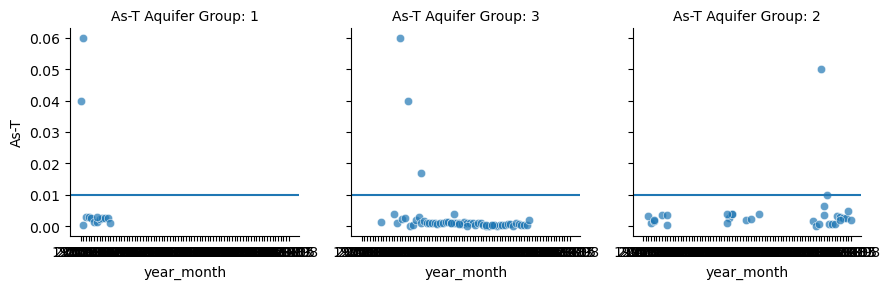

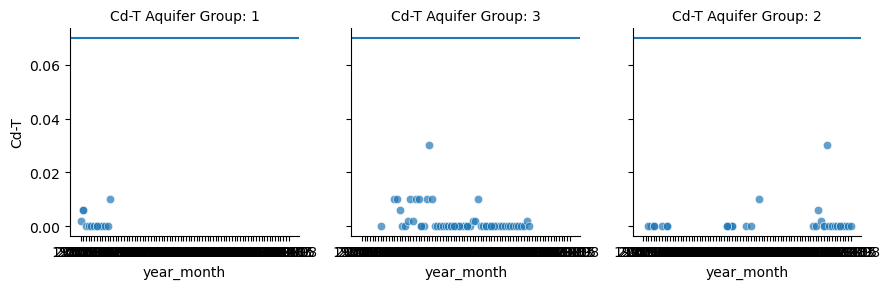

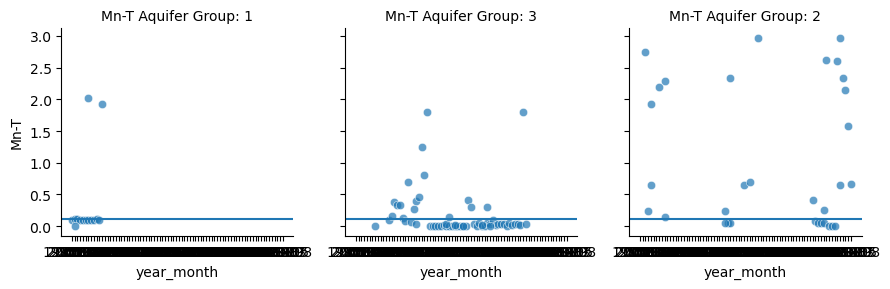

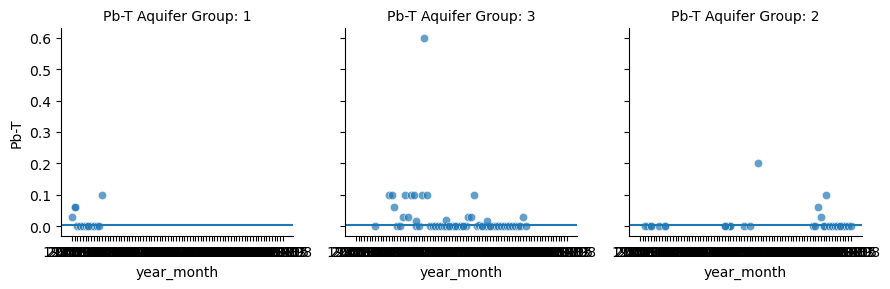

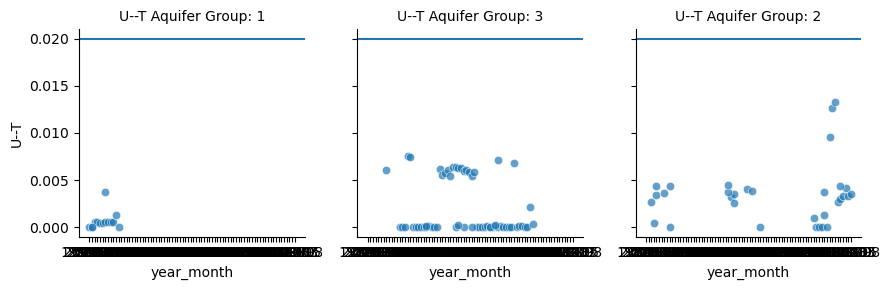

In [11]:
Total_Metals = df_SWICLorSCorSCtime[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group', 'year_month']]

# Assuming Total_Metals DataFrame already exists
As = sns.FacetGrid(Total_Metals, col="Aquifer Group")
As.map(sns.scatterplot, "year_month", 'As-T', alpha=.7)
As.map(lambda x, **kwargs: plt.axhline(y=0.01, **kwargs), "year_month")
As.set_titles("As-T Aquifer Group: {col_name}")  # Setting title for each subplot

Cd = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Cd.map(sns.scatterplot, "year_month", 'Cd-T', alpha=.7)
Cd.map(lambda x, **kwargs: plt.axhline(y=0.07, **kwargs), "year_month")
Cd.set_titles("Cd-T Aquifer Group: {col_name}")  # Setting title for each subplot

Mn = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Mn.map(sns.scatterplot, "year_month", 'Mn-T', alpha=.7)
Mn.map(lambda x, **kwargs: plt.axhline(y=0.12, **kwargs), "year_month")
Mn.set_titles("Mn-T Aquifer Group: {col_name}")  # Setting title for each subplot

Pb = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Pb.map(sns.scatterplot, "year_month", 'Pb-T', alpha=.7)
Pb.map(lambda x, **kwargs: plt.axhline(y=0.005, **kwargs), "year_month")
Pb.set_titles("Pb-T Aquifer Group: {col_name}")  # Setting title for each subplot

UT = sns.FacetGrid(Total_Metals, col="Aquifer Group")
UT.map(sns.scatterplot, "year_month", 'U--T', alpha=.7)
UT.map(lambda x, **kwargs: plt.axhline(y=0.02, **kwargs), "year_month")
UT.set_titles("U--T Aquifer Group: {col_name}")  # Setting title for each subplot

#plt.suptitle("Well Water Samples with As, Mn, Pb and U Concentrations over Canadian Drinking Water Standards", fontsize=12, y=1.02)
plt.tight_layout()  # This line is to prevent overlapping of the title and the top plot
plt.show()
#plt.savefig('Figures/metalsoverCADdrinkingwaterSWIsc.png')

Datat.columns


#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols = ['pH']
cleaned_dataset_array = replace_outliers_with_iqr(Datat[numeric_cols], 1.5)


In [6]:
'''
Handling Outliers

Notes:  
To prevent more outlier removal, use MAD score.  ID df_SWICLorSCorSC style.  Will not to Mahalanobis method due to complexity

Decided to use threshold score instead.  MAD scores takes away from metals being past the drinking water standard and SWI values

Source:
https://stats.stackexchange.com/questions/591853/interquartile-range-finding-more-than-10-times-outliers-than-zscore#:~:text=Yes%20%2D%20using%20the%20IQR%20method,will%20find%20lots%20of%20outliers.
https://saturncloud.io/blog/how-to-detect-and-exclude-outliers-in-a-pandas-dataframe/#:~:text=The%20IQR%20can%20be%20calculated,can%20be%20considered%20an%20outlier.
https://www.analyticsvidhya.com/blog/2021/05/detecting-and-treating-outliers-treating-the-odd-one-out/
'''

def replace_outliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        upper_threshold = Q3 + k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
        cleaned_dataset.loc[cleaned_dataset[col] > upper_threshold, col] = upper_threshold
    return cleaned_dataset

#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols1 = ['pH', 'Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT']
cleaned_dataset_array1 = replace_outliers_with_iqr(df_SWICLorSCorSC[numeric_cols1], 1.5)
df_SWICLorSCorSC[numeric_cols1] = cleaned_dataset_array1


def replace_outliers_with_threshold(dataset, threshold_multiplier=3):
    """
    Replace outliers in a dataset with the threshold value based on the Median Absolute Deviation (MAD).

    Parameters:
    - dataset: DataFrame containing the dataset.
    - threshold_multiplier: Multiple of the MAD to be used as the threshold (default: 3).

    Returns:
    - cleaned_dataset: DataFrame with outliers replaced by the threshold.
    """
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        col_values = cleaned_dataset[col].values
        median = np.median(col_values)
        mad = np.median(np.abs(col_values - median))
        lower_threshold = median - threshold_multiplier * mad
        upper_threshold = median + threshold_multiplier * mad
        high_outliers = (col_values - median) > upper_threshold
        cleaned_dataset.loc[high_outliers, col] = upper_threshold
        # Update col_values after replacing high outliers
        col_values = cleaned_dataset[col].values
        low_outliers = (col_values - median) < lower_threshold
        cleaned_dataset.loc[low_outliers, col] = lower_threshold
    return cleaned_dataset
'''
# Assume df_SWICLorSCorSC is your DataFrame
numeric_cols = [, 

# Call your function on just the numeric columns
cleaned_dataset_array = replace_outliers_with_threshold(df_SWICLorSCorSC[numeric_cols], threshold_multiplier=3)

# Convert the numpy array back to a DataFrame
cleaned_dataset = pd.DataFrame(cleaned_dataset_array, columns=numeric_cols, index=df_SWICLorSCorSC.index)

df_SWICLorSCorSC[numeric_cols] = cleaned_dataset
'''

df_SWICLorSCorSCpastremoval1 = df_SWICLorSCorSC.copy() #This is incase I screw up. Can be commented out.

#cleaned_dataset.to_csv('cleaned_dataset.csv')

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_36960\3997573836.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_SWICLorSCorSC[numeric_cols1] = cleaned_dataset_array1
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_36960\3997573836.py:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_SWICLorSCorSC[numeric_cols] = cleaned_dataset


In [7]:
from sklearn.preprocessing import PowerTransformer

# Create a PowerTransformer object
pt = PowerTransformer(method='yeo-johnson')

# Define the column names you want to transform
cols_to_transform = ['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP']
# Apply the transformation to the specified columns
df_SWICLorSCorSC[cols_to_transform] = pt.fit_transform(df_SWICLorSCorSC[cols_to_transform])

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_36960\583112676.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_SWICLorSCorSC[cols_to_transform] = pt.fit_transform(df_SWICLorSCorSC[cols_to_transform])


In [8]:
df_SWICLorSCorSC.shape

(106, 24)

In [9]:
#df_SWICLorSCorSC.to_csv('df_SWICLorSCorSC.csv')

In [10]:
df_SWICLorSCorSC.shape

(106, 24)

In [11]:
df_SWICLorSCorSC.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group'],
      dtype='object')

In [12]:
# import pandas and numpy if they're not already imported
import pandas as pd
import numpy as np

# assuming `df` is your DataFrame
selected_columns = df_SWICLorSCorSC.iloc[:, :23]  # select the first 26 columns
group_column = df_SWICLorSCorSC.iloc[:, 23]  # select the 27th column

# group the selected columns by the values in the group column
grouped = selected_columns.groupby(group_column)

# get the unique group names
groups = df_SWICLorSCorSC.iloc[:, 23].unique()

# calculate summary statistics and percentiles for each group
all_summaries3 = []  # list to hold summary dataframes for each group
for group in groups:
    # select data for this group
    this_group = grouped.get_group(group)

    # calculate summary statistics
    summary = this_group.agg(['mean', 'var', 'std', 'min', 'max', 'skew', 'median', pd.DataFrame.kurt])

    # calculate percentiles and add them to the summary
    for q in [0.1, 0.5, 0.9]:
        summary.loc[f'{q*100}% percentile'] = this_group.quantile(q)

    # calculate coefficient of variation and add it to the summary
    summary.loc['cv'] = this_group.std() / this_group.mean()

    # add the group name as the top level of the index
    summary.index = pd.MultiIndex.from_product([[group], summary.index])

    # add this group's summary to the list
    all_summaries3.append(summary)

# concatenate all the group summaries into one DataFrame
summary_df3 = pd.concat(all_summaries3)

# save to CSVWhich is the best given datasets have range between 0.000001-0.027475 in one column and 3580.000000-0.025000 in another?


summary_df3.to_csv('Stats/statssummarySWICLorSC.csv')

# check the DataFrame
print(summary_df3)

                    Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
1 mean                          0.149222  0.594450  0.889134 -0.320596   
  var                           0.226584  0.540217  0.097257  1.114935   
  std                           0.476008  0.734994  0.311861  1.055905   
  min                          -1.466562 -0.959766  0.316780 -1.102644   
  max                           0.437808  1.368168  1.577669  1.253101   
  skew                         -3.455500 -1.022221  0.129614  0.924045   
  median                        0.276041  0.851579  0.950880 -0.906989   
  kurt                         12.443049 -0.165217  1.264660 -1.163380   
  10.0% percentile              0.077508 -0.377685  0.500187 -1.102644   
  50.0% percentile              0.276041  0.851579  0.950880 -0.906989   
  90.0% percentile              0.368135  1.293243  1.119322  1.253101   
  cv                            3.189929  1.236428  0.350747 -3.293569   
3 mean                         -0.2446

In [13]:
correlation_matSWICLorSC = df_SWICLorSCorSC.corr()
correlation_matSWICLorSC.to_csv('Stats/correlation_matafterSWICLorSC.csv')
print(correlation_matSWICLorSC)


                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.233521  0.233400 -0.251940   
As-T                                 0.233521  1.000000  0.397796  0.070779   
Ca-T                                 0.233400  0.397796  1.000000  0.088994   
Cd-T                                -0.251940  0.070779  0.088994  1.000000   
Chlrid:D                            -0.377990 -0.379764 -0.443107  0.262097   
Fe-T                                -0.086181  0.342126  0.197472  0.476616   
Mn-T                                -0.165933  0.422753  0.206668  0.161569   
N.Kjel:T                             0.015538 -0.257594 -0.060574 -0.042061   
P--T                                 0.264769  0.097324  0.074066  0.101529   
Pb-T                                -0.300400  0.102247 -0.013216  0.781028   
Residue Filterable 1.0u             -0.256882  0.050091 -0.085703  0.438130   
Specific Conductance                -0.278608 -0.100

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_36960\806234296.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matSWICLorSC = df_SWICLorSCorSC.corr()


In [14]:
correlation_tauSWICLorSC = df_SWICLorSCorSC.corr(method='kendall')
print(correlation_tauSWICLorSC)
correlation_tauSWICLorSC.to_csv('Stats/correlation_tauSWICLorSC.csv')

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_36960\3822537758.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_tauSWICLorSC = df_SWICLorSCorSC.corr(method='kendall')


                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.166729  0.074769 -0.128815   
As-T                                 0.166729  1.000000  0.254480  0.041379   
Ca-T                                 0.074769  0.254480  1.000000  0.000000   
Cd-T                                -0.128815  0.041379  0.000000  1.000000   
Chlrid:D                            -0.278783 -0.307728 -0.281301  0.192607   
Fe-T                                 0.005397  0.271819  0.120195  0.322522   
Mn-T                                -0.169137  0.267719  0.066771  0.132621   
N.Kjel:T                             0.024345 -0.180963  0.023873 -0.000998   
P--T                                 0.110526  0.150701  0.067085  0.104434   
Pb-T                                -0.183416  0.070339 -0.059913  0.591998   
Residue Filterable 1.0u             -0.176587 -0.000784 -0.075801  0.334019   
Specific Conductance                -0.224071 -0.093

In [15]:
correlation_rhoSWICLorSC = df_SWICLorSCorSC.corr(method='spearman')
correlation_rhoSWICLorSC.to_csv('Stats/correlation_rhoSWICLorSC.csv')
print(correlation_rhoSWICLorSC)

                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.238905  0.139710 -0.174539   
As-T                                 0.238905  1.000000  0.357900  0.072504   
Ca-T                                 0.139710  0.357900  1.000000 -0.003030   
Cd-T                                -0.174539  0.072504 -0.003030  1.000000   
Chlrid:D                            -0.415220 -0.412326 -0.403648  0.260726   
Fe-T                                -0.022451  0.352672  0.153481  0.426603   
Mn-T                                -0.250732  0.430041  0.091785  0.175088   
N.Kjel:T                             0.027311 -0.253872  0.031272 -0.011271   
P--T                                 0.162235  0.199067  0.086843  0.137763   
Pb-T                                -0.255245  0.095852 -0.079239  0.740784   
Residue Filterable 1.0u             -0.232431 -0.005121 -0.088009  0.418200   
Specific Conductance                -0.275608 -0.121

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_36960\1114351889.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_rhoSWICLorSC = df_SWICLorSCorSC.corr(method='spearman')


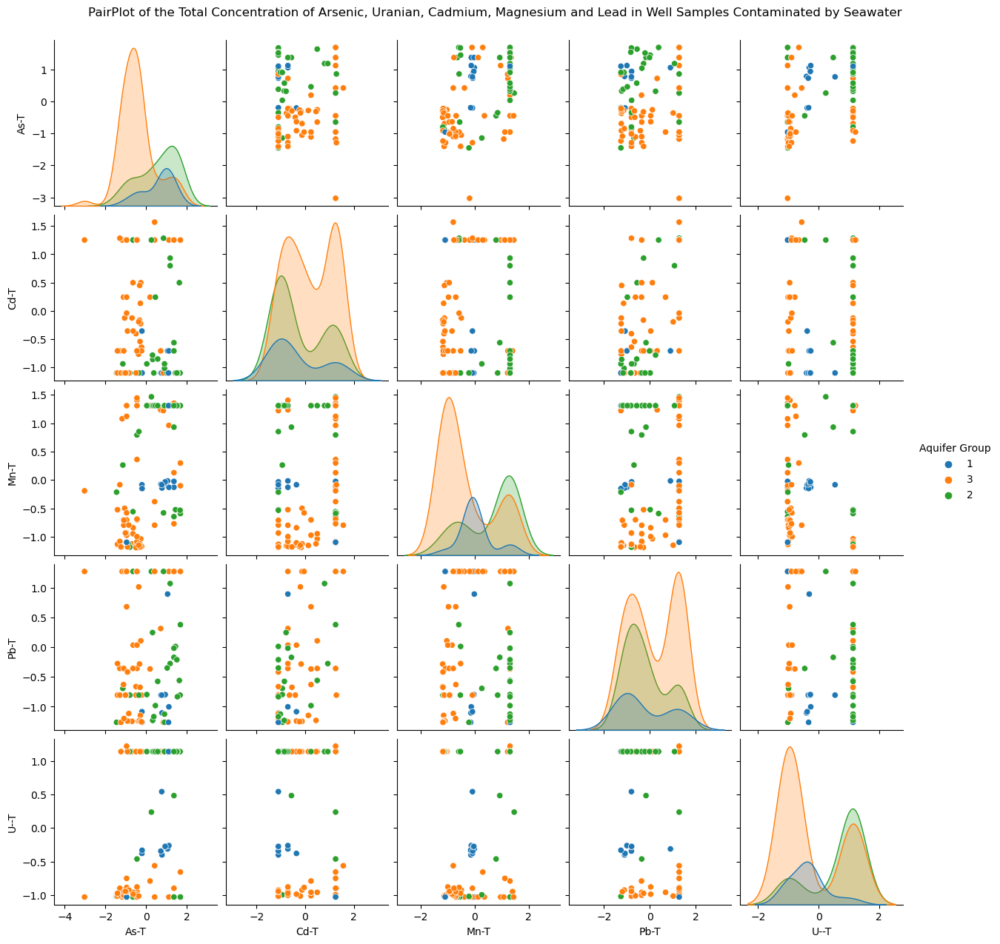

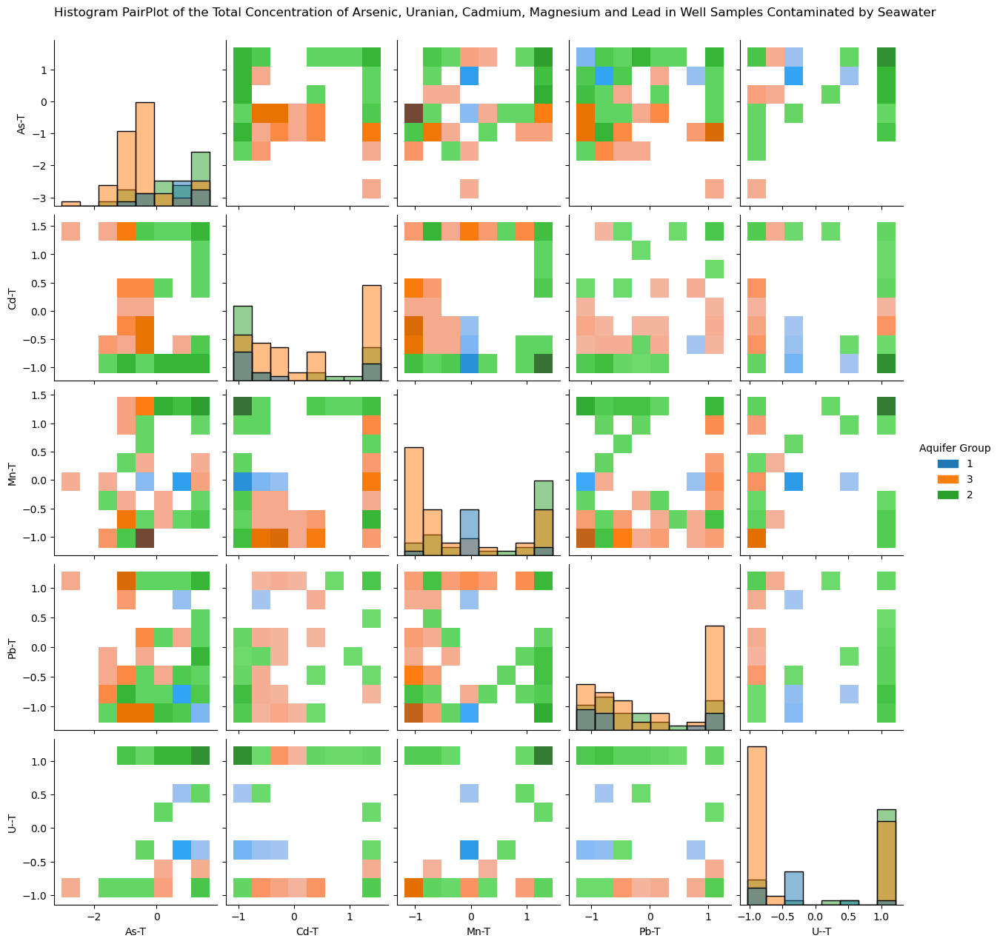

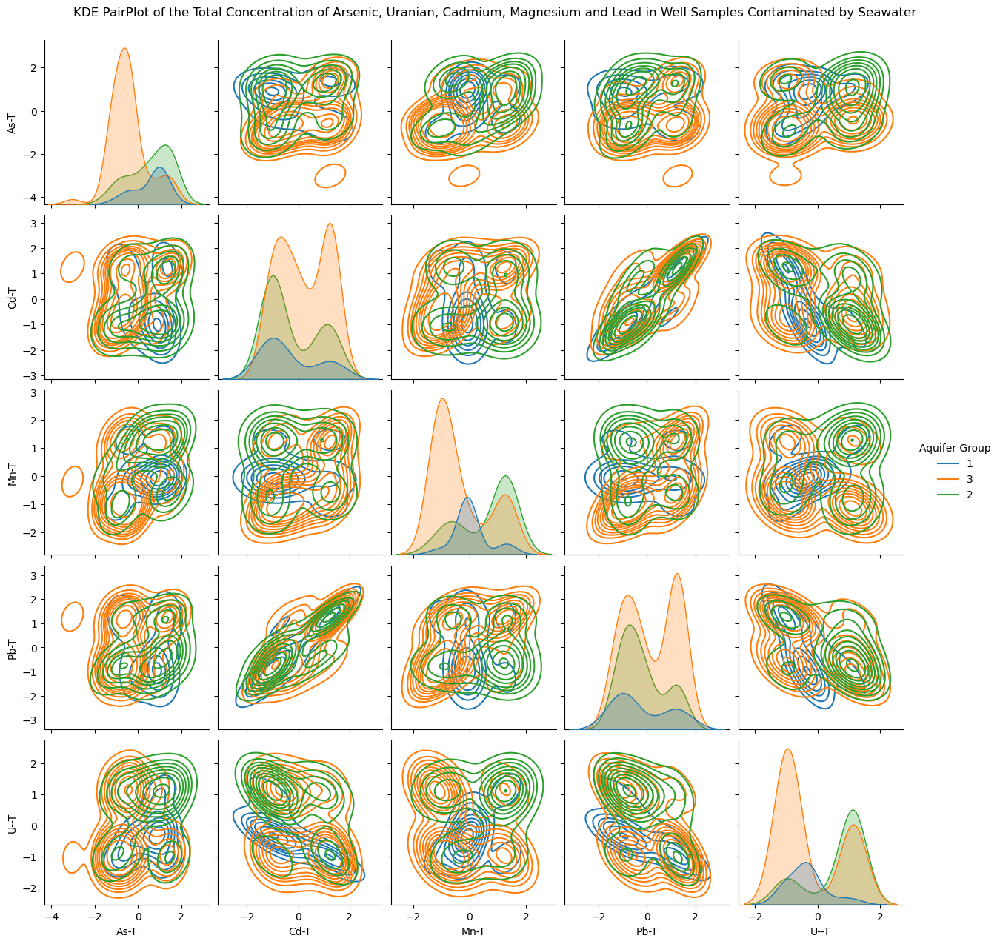

In [16]:
Metals_Total = df_SWICLorSCorSC[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group']]
Metalsg = sns.pairplot(Metals_Total, hue="Aquifer Group")
Metalsg.fig.suptitle("PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples Contaminated by Seawater", y=1.02)
plt.savefig('Figures/pairplotmetalsSWICLorSC.png') # Save the first figure

Metalsh = sns.pairplot(Metals_Total, hue="Aquifer Group", kind="hist")
Metalsh.fig.suptitle("Histogram PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples Contaminated by Seawater", y=1.02)
plt.savefig('Figures/histplotmetalsSWICLorSC.png') 

Metalsf = sns.pairplot(Metals_Total, hue="Aquifer Group", kind="kde")
Metalsf.fig.suptitle("KDE PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples Contaminated by Seawater", y=1.02)
plt.savefig('Figures/KDEplotmetalsSWICLorSC.png') 


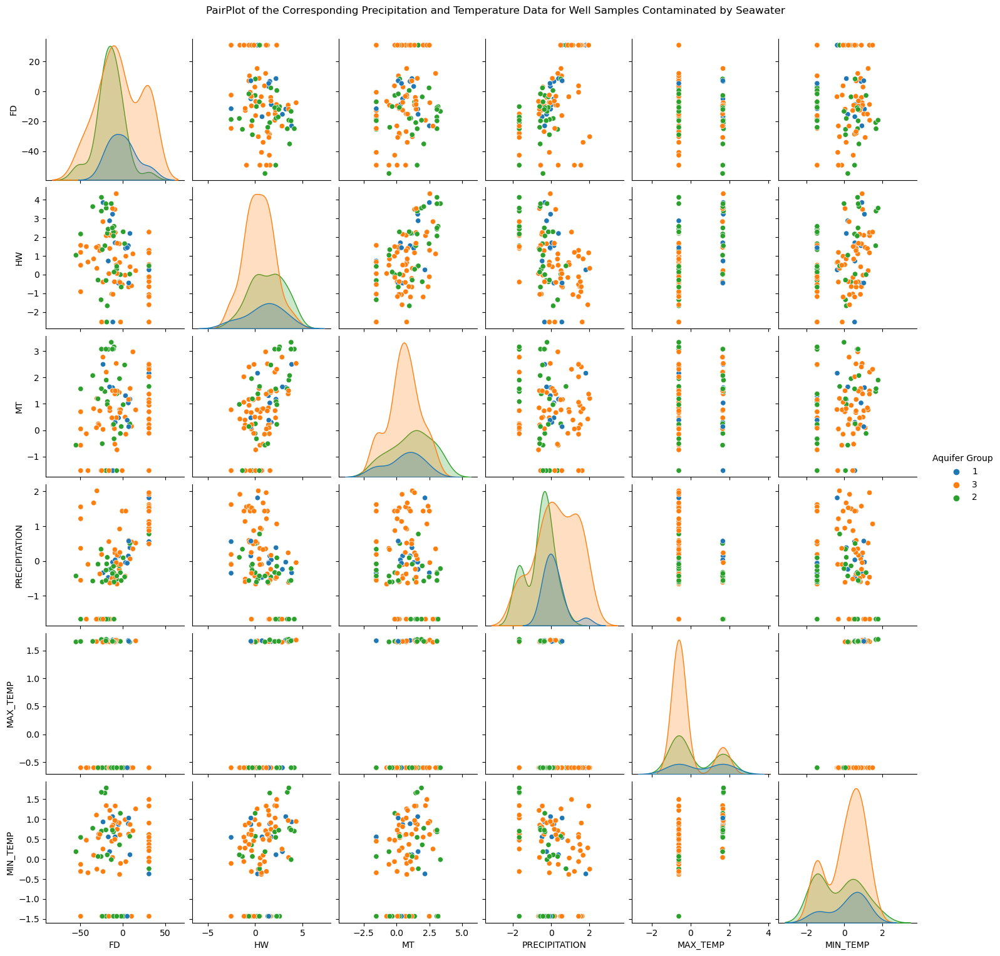

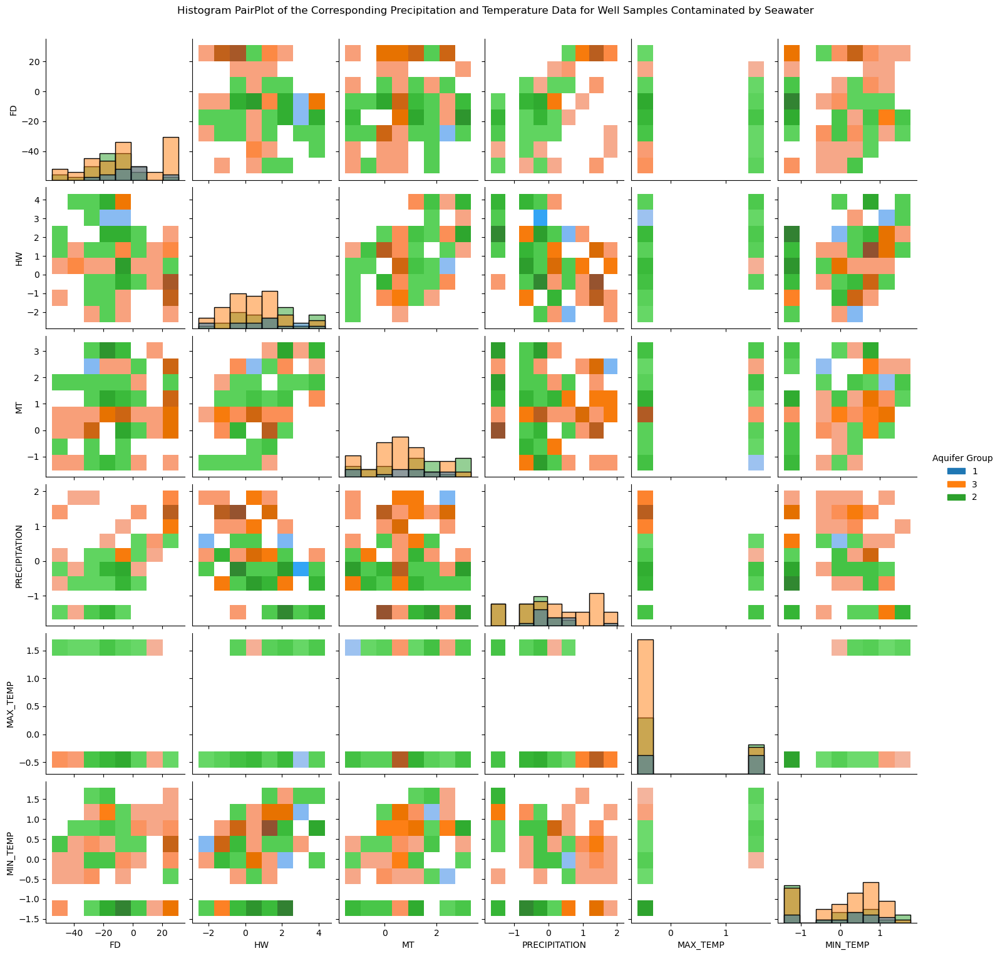

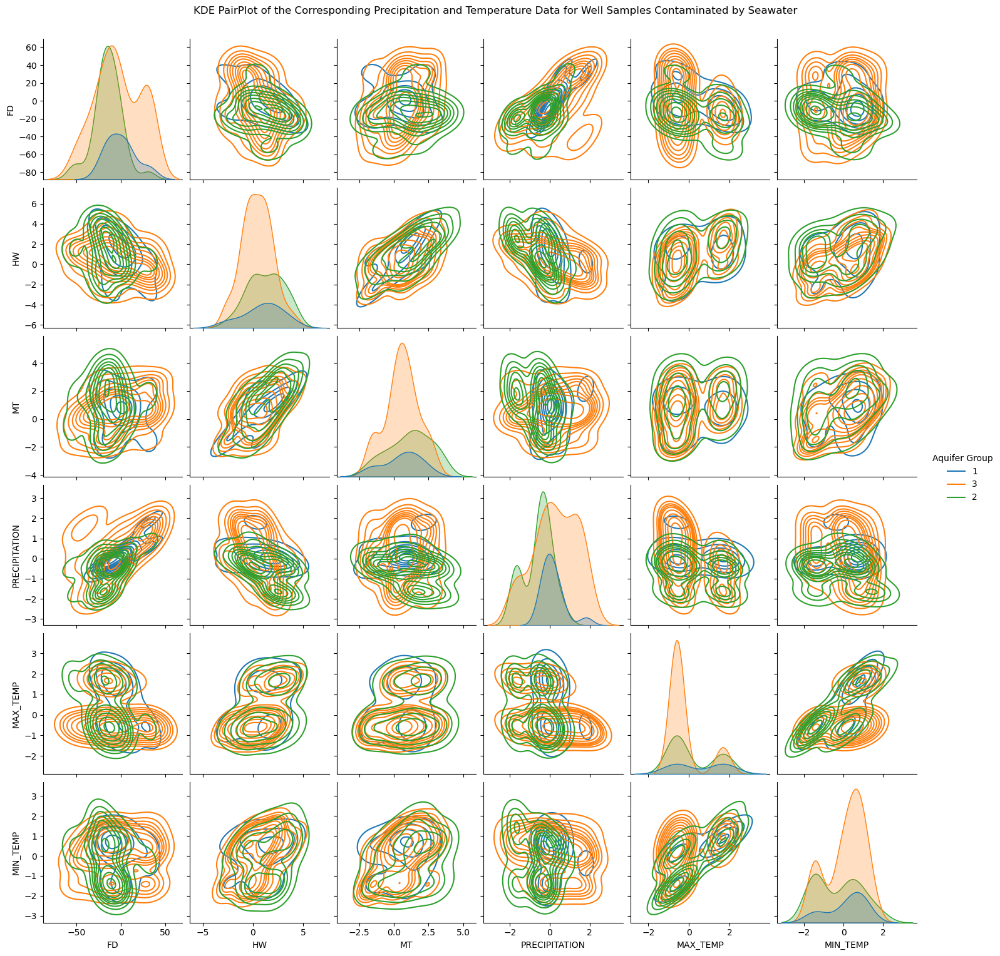

In [17]:
Precept = df_SWICLorSCorSC[['FD', 'HW', 'MT', 'Aquifer Group', 'PRECIPITATION', 'MAX_TEMP', 'MIN_TEMP']]
Preceptg= sns.pairplot(Precept, hue="Aquifer Group")
Preceptg.fig.suptitle("PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples Contaminated by Seawater", y=1.02)
plt.savefig('Figures/pairplotPreceptSWICLorSC.png') # Save the first figure

Precepth = sns.pairplot(Precept, hue="Aquifer Group", kind="hist")
Precepth.fig.suptitle("Histogram PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples Contaminated by Seawater", y=1.02)
plt.savefig('Figures/histplotPreceptSWICLorSC.png') 

Preceptf = sns.pairplot(Precept, hue="Aquifer Group", kind="kde")
Preceptf.fig.suptitle("KDE PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples Contaminated by Seawater", y=1.02)
plt.savefig('Figures/KDEplotPreceptSWICLorSC.png') 

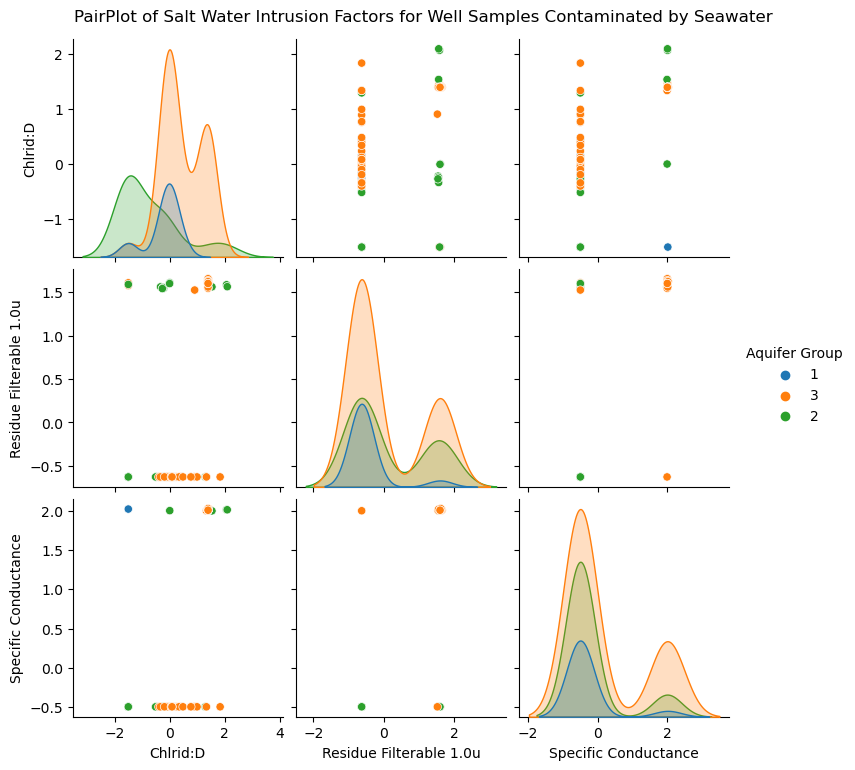

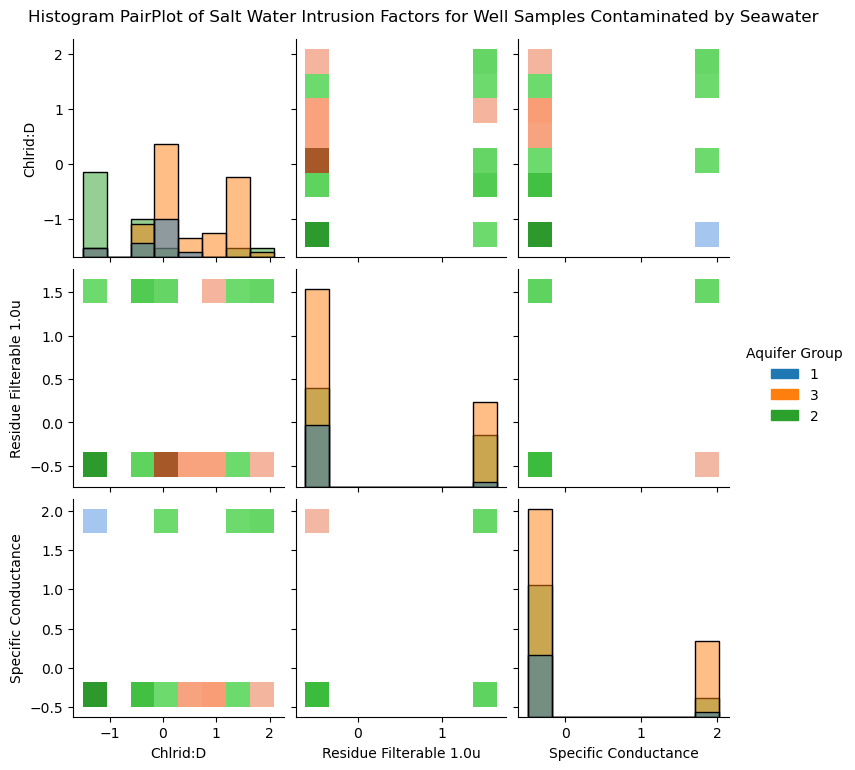

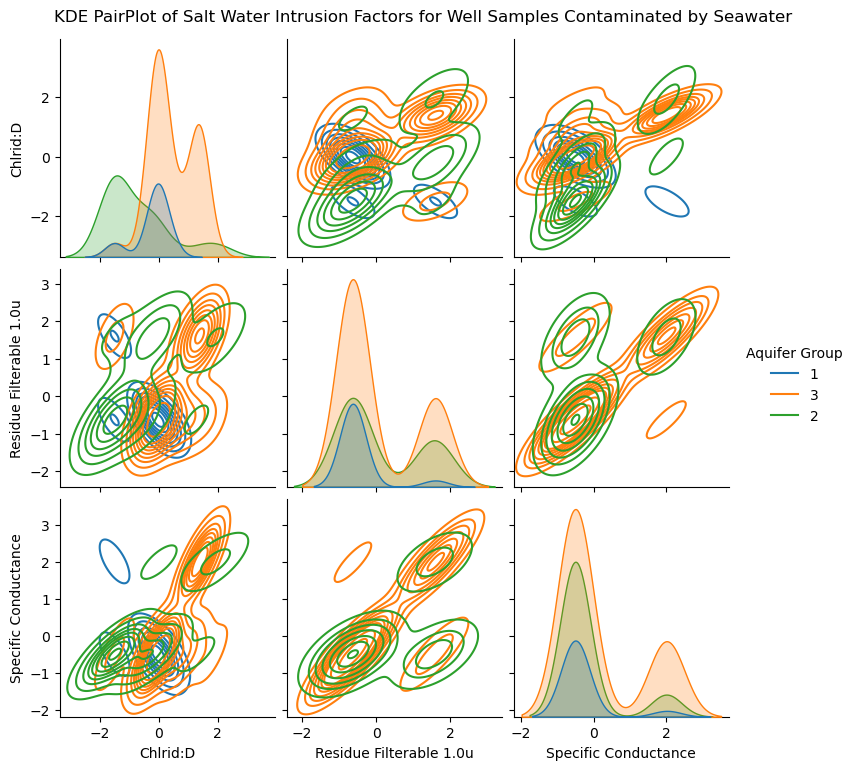

In [18]:
SWID = df_SWICLorSCorSC[['Chlrid:D', 'Residue Filterable 1.0u', 'Specific Conductance', 'Aquifer Group']]
SWIDg= sns.pairplot(SWID, hue="Aquifer Group")
SWIDg.fig.suptitle("PairPlot of Salt Water Intrusion Factors for Well Samples Contaminated by Seawater", y=1.02)
plt.savefig('Figures/pairplotSWIDSWICLorSC.png') # Save the first figure

SWIDh = sns.pairplot(SWID, hue="Aquifer Group", kind="hist")
SWIDh.fig.suptitle("Histogram PairPlot of Salt Water Intrusion Factors for Well Samples Contaminated by Seawater", y=1.02)
plt.savefig('Figures/histplotSWIDSWICLorSC.png') 

SWIDf = sns.pairplot(SWID, hue="Aquifer Group", kind="kde")
SWIDf.fig.suptitle("KDE PairPlot of Salt Water Intrusion Factors for Well Samples Contaminated by Seawater", y=1.02)
plt.savefig('Figures/KDEplotSWIDSWICLorSC.png') 

In [19]:
OthersD = df_SWICLorSCorSC[['Alkalinity Total 4.5', 'Ca-T', 'Fe-T',
       'N.Kjel:T', 'P--T', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T', 'Aquifer Group']]

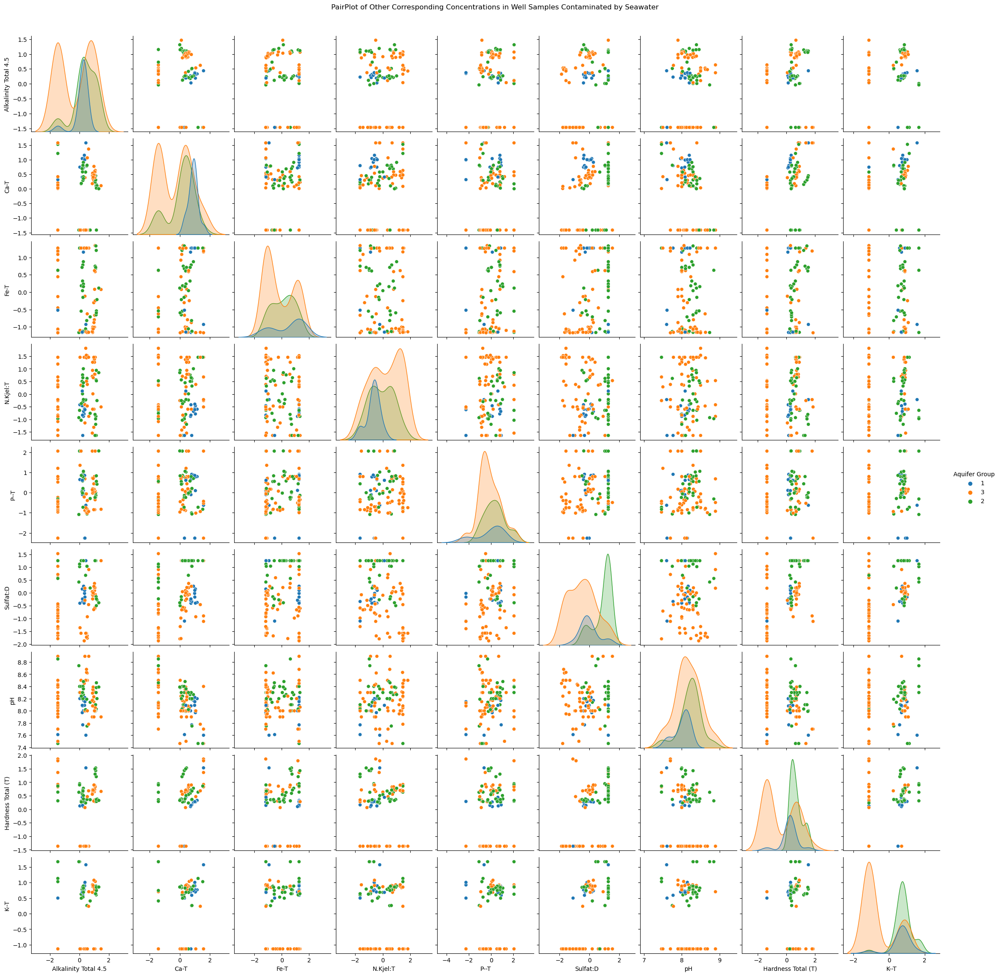

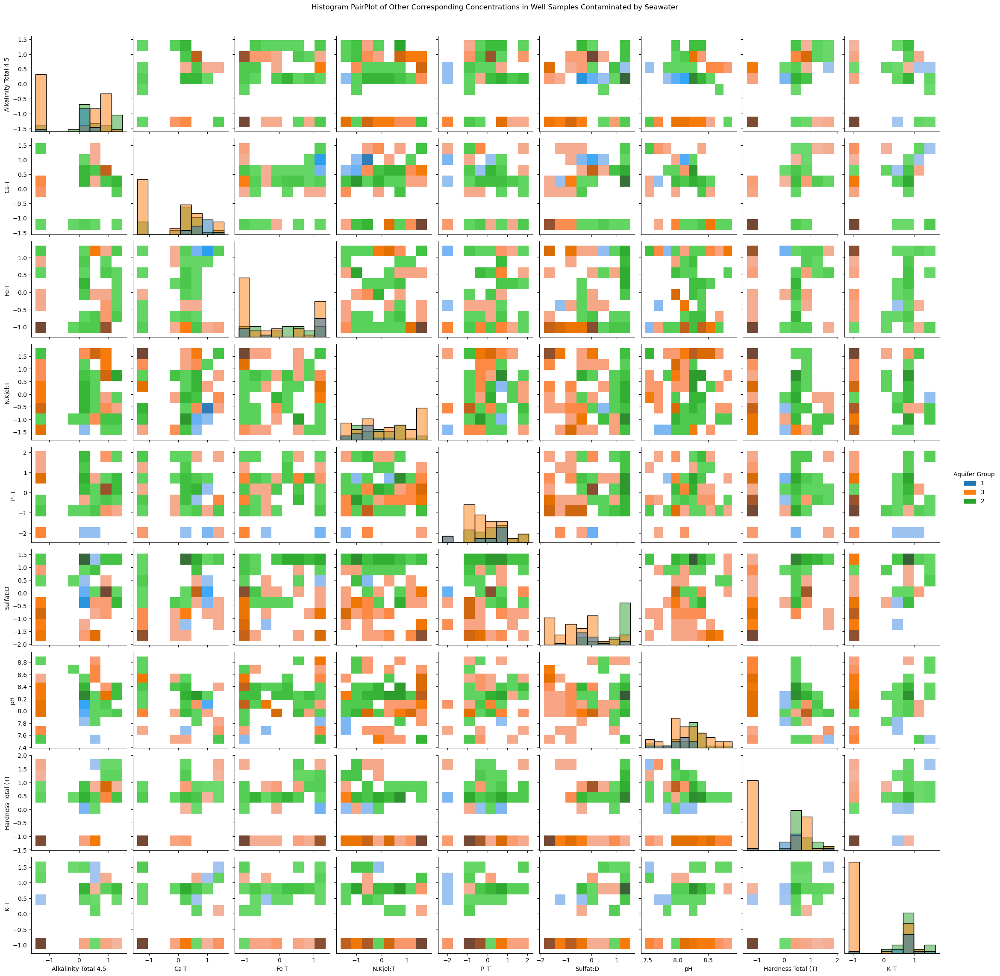

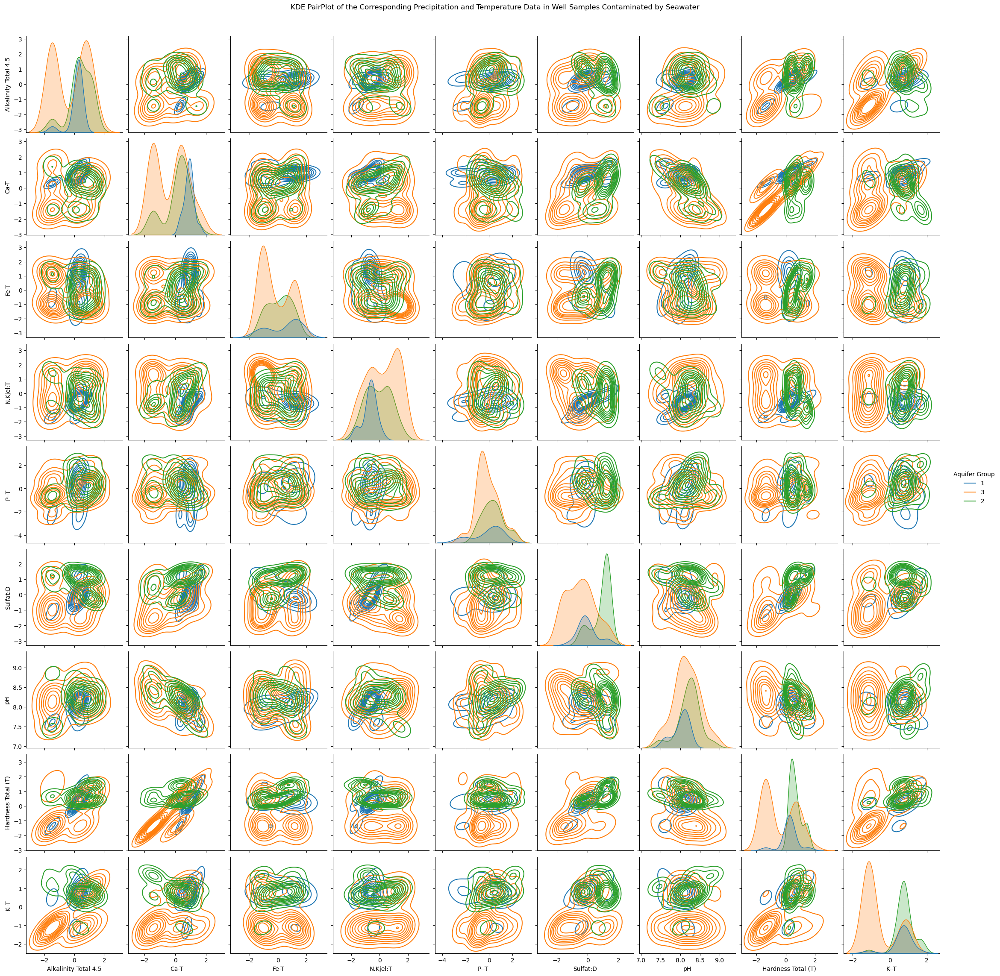

In [20]:
OthersDg= sns.pairplot(OthersD, hue="Aquifer Group")
OthersDg.fig.suptitle("PairPlot of Other Corresponding Concentrations in Well Samples Contaminated by Seawater", y=1.02)
plt.savefig('Figures/pairplotOthersDSWICLorSC.png') # Save the first figure

OthersDh = sns.pairplot(OthersD, hue="Aquifer Group", kind="hist")
OthersDh.fig.suptitle("Histogram PairPlot of Other Corresponding Concentrations in Well Samples Contaminated by Seawater", y=1.02)
plt.savefig('Figures/histplotOthersDSWICLorSC.png') 

Othersf = sns.pairplot(OthersD, hue="Aquifer Group", kind="kde")
Othersf.fig.suptitle("KDE PairPlot of the Corresponding Precipitation and Temperature Data in Well Samples Contaminated by Seawater", y=1.02)
plt.savefig('Figures/KDEplotOthersSWICLorSC.png') 

In [21]:
df_SWICLorSCorSC.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group'],
      dtype='object')

In [22]:
df_SWICLorSCorSC.shape

(106, 24)

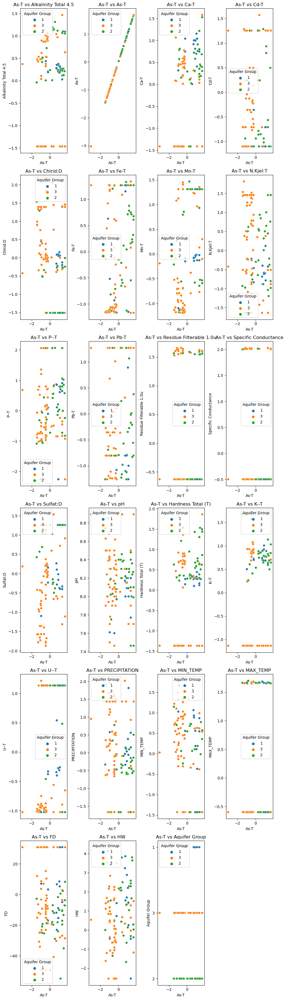

<Figure size 1000x800 with 0 Axes>

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df_SWICLorSCorSC is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_SWICLorSCorSC.columns if col != 'MT']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='As-T', y=pmetal, data=df_SWICLorSCorSC, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'As-T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/ASTSWICLorSC.png') 

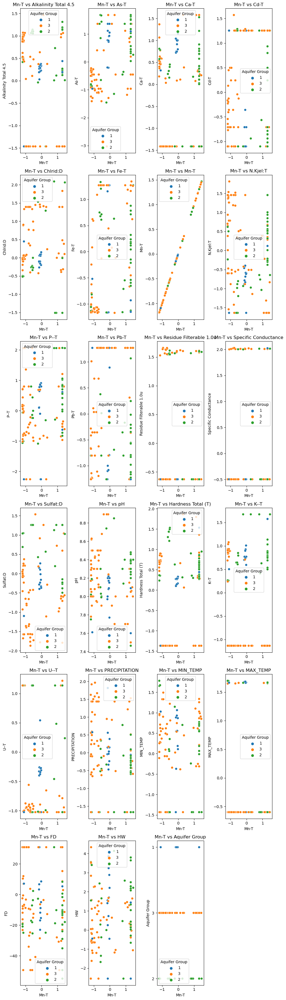

<Figure size 1000x800 with 0 Axes>

In [24]:
# Assuming df_SWICLorSCorSC is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_SWICLorSCorSC.columns if col != 'MT']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='Mn-T', y=pmetal, data=df_SWICLorSCorSC, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'Mn-T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/MnTSWICLorSC.png') 

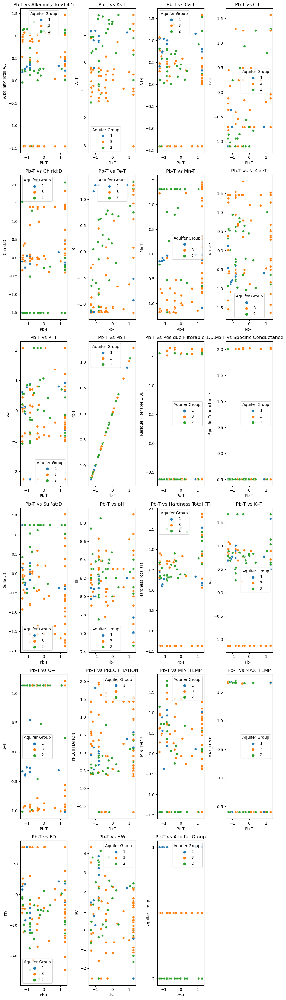

<Figure size 1000x800 with 0 Axes>

In [25]:
# Assuming df_SWICLorSCorSC is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_SWICLorSCorSC.columns if col != 'MT']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='Pb-T', y=pmetal, data=df_SWICLorSCorSC, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'Pb-T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/PbTSWICLorSC.png') 

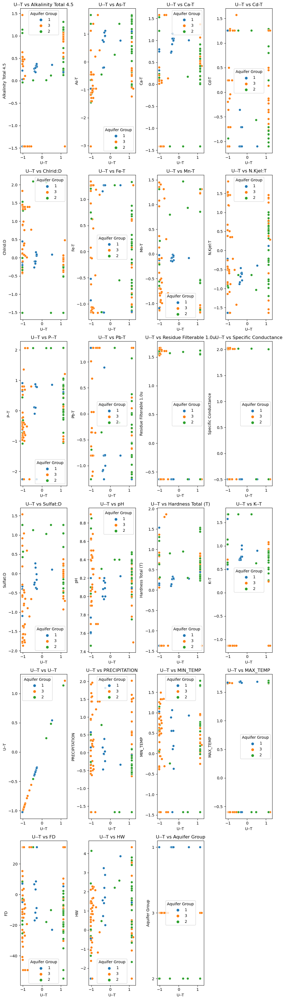

<Figure size 1000x800 with 0 Axes>

In [26]:
# Assuming df_SWICLorSCorSC is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_SWICLorSCorSC.columns if col != 'MT']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='U--T', y=pmetal, data=df_SWICLorSCorSC, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'U--T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/UTSWICLorSC.png') 

In [27]:
df_SWICLorSCorSCtime = Datawithtime[(Datat['Chlrid:D'] > 150) | (Datat['Specific Conductance'] > 1000)]
cleaned_dataset_array2 = replace_outliers_with_iqr(df_SWICLorSCorSCtime[numeric_cols1], 1.5)
df_SWICLorSCorSCtime[numeric_cols1] = cleaned_dataset_array2
cleaned_dataset_array2a = replace_outliers_with_threshold(df_SWICLorSCorSCtime[numeric_cols], threshold_multiplier=3)
cleaned_dataset2 = pd.DataFrame(cleaned_dataset_array2a, columns=numeric_cols, index=df_SWICLorSCorSCtime.index)
df_SWICLorSCorSCtime[numeric_cols] = cleaned_dataset2

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_36960\3501896421.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_SWICLorSCorSCtime[numeric_cols1] = cleaned_dataset_array2
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_36960\3501896421.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_SWICLorSCorSCtime[numeric_cols] = cleaned_dataset2


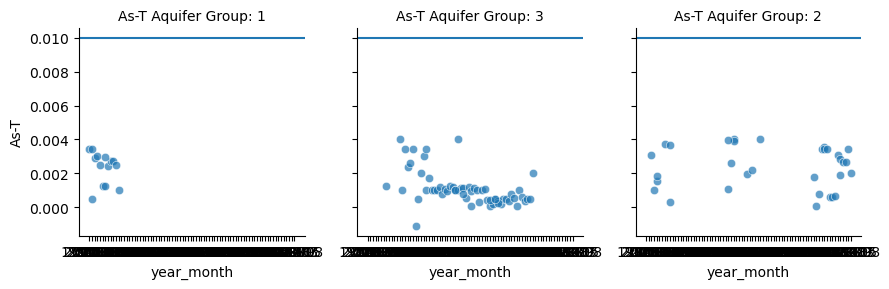

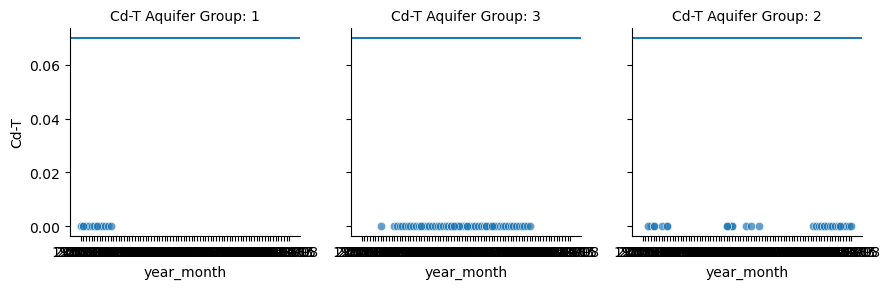

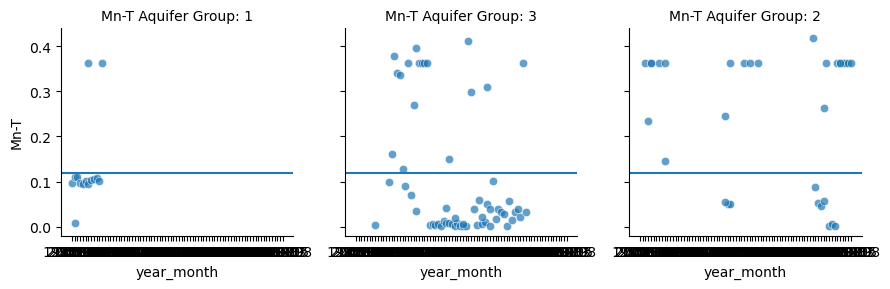

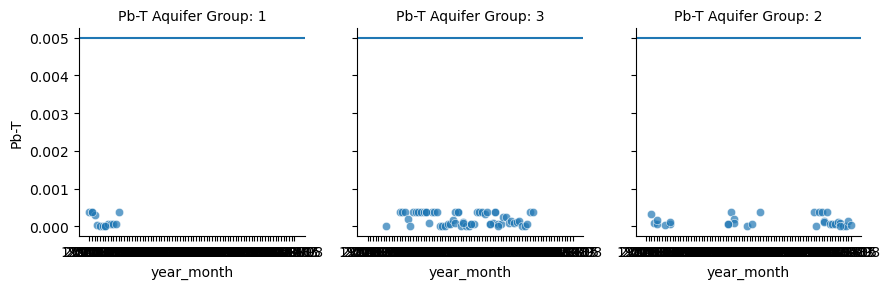

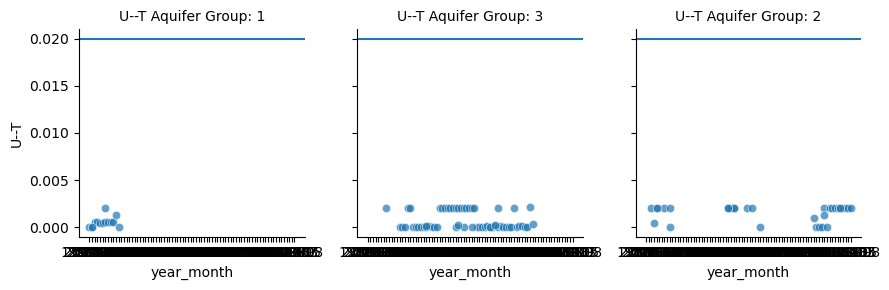

<Figure size 1000x800 with 0 Axes>

In [28]:
Total_Metals = df_SWICLorSCorSCtime[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group', 'year_month']]

# Assuming Total_Metals DataFrame already exists
As = sns.FacetGrid(Total_Metals, col="Aquifer Group")
As.map(sns.scatterplot, "year_month", 'As-T', alpha=.7)
As.map(lambda x, **kwargs: plt.axhline(y=0.01, **kwargs), "year_month")
As.set_titles("As-T Aquifer Group: {col_name}")  # Setting title for each subplot

Cd = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Cd.map(sns.scatterplot, "year_month", 'Cd-T', alpha=.7)
Cd.map(lambda x, **kwargs: plt.axhline(y=0.07, **kwargs), "year_month")
Cd.set_titles("Cd-T Aquifer Group: {col_name}")  # Setting title for each subplot

Mn = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Mn.map(sns.scatterplot, "year_month", 'Mn-T', alpha=.7)
Mn.map(lambda x, **kwargs: plt.axhline(y=0.12, **kwargs), "year_month")
Mn.set_titles("Mn-T Aquifer Group: {col_name}")  # Setting title for each subplot

Pb = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Pb.map(sns.scatterplot, "year_month", 'Pb-T', alpha=.7)
Pb.map(lambda x, **kwargs: plt.axhline(y=0.005, **kwargs), "year_month")
Pb.set_titles("Pb-T Aquifer Group: {col_name}")  # Setting title for each subplot

UT = sns.FacetGrid(Total_Metals, col="Aquifer Group")
UT.map(sns.scatterplot, "year_month", 'U--T', alpha=.7)
UT.map(lambda x, **kwargs: plt.axhline(y=0.02, **kwargs), "year_month")
UT.set_titles("U--T Aquifer Group: {col_name}")  # Setting title for each subplot

#plt.suptitle("Well Water Samples with As, Mn, Pb and U Concentrations over Canadian Drinking Water Standards", fontsize=12, y=1.02)
plt.tight_layout()  # This line is to prevent overlapping of the title and the top plot
plt.show()
plt.savefig('Figures/metalsoverCADdrinkingwaterSWICLorSC.png')

In [29]:
CANDMetalspre = df_SWICLorSCorSCtime[['OBSWELL', 'As-T', 'Mn-T', 'Pb-T', 'U--T']]
filtered_dfAs = CANDMetalspre[(CANDMetalspre['As-T'] >= 0.01)]
obs_well_valuesAs = filtered_dfAs['OBSWELL']
obs_well_valuesAs.shape

(0,)

In [30]:
filtered_dfMn = CANDMetalspre[(CANDMetalspre['Mn-T'] >= 0.12)]
obs_well_valuesMn = filtered_dfMn['OBSWELL']
obs_well_valuesMn.shape

(41,)

In [31]:
filtered_dfPb = CANDMetalspre[(CANDMetalspre['Pb-T'] >= 0.005)]
obs_well_valuesPb = filtered_dfPb['OBSWELL']
obs_well_valuesPb.shape

(0,)

In [32]:
filtered_dfU = CANDMetalspre[(CANDMetalspre['U--T'] >= 0.02)]
obs_well_valuesU = filtered_dfU['OBSWELL']
obs_well_valuesU.shape

(0,)

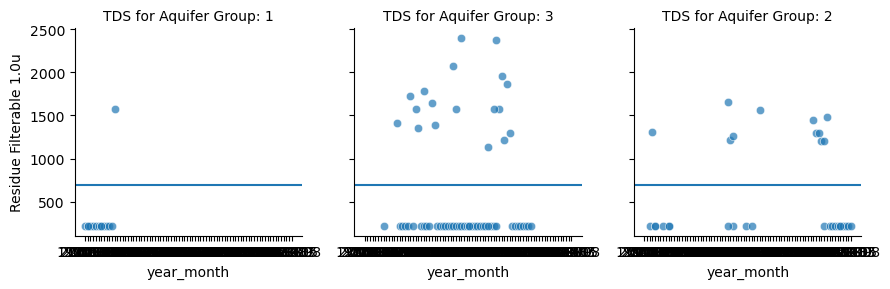

In [33]:
'''
Graphs of Saltwater intrusion
'''
SI_values = df_SWICLorSCorSCtime[['year_month', 'Residue Filterable 1.0u','Specific Conductance', 'Chlrid:D', 'Aquifer Group']]


TDS = sns.FacetGrid(SI_values, col="Aquifer Group")
TDS.map(sns.scatterplot, "year_month", "Residue Filterable 1.0u", alpha=.7)
TDS.map(lambda x, **kwargs: plt.axhline(y=700, **kwargs), "year_month")
TDS.set_titles("TDS for Aquifer Group: {col_name}")  # Setting title for each subplot
'''
SC = sns.FacetGrid(SI_values, col="Aquifer Group")
SC.map(sns.scatterplot, "year_month", 'Specific Conductance', alpha=.7)
SC.map(lambda x, **kwargs: plt.axhline(y=1000, **kwargs), "year_month")
SC.set_titles("Specific Conductance for Aquifer Group: {col_name}")  # Setting title for each subplot

Cld = sns.FacetGrid(SI_values, col="Aquifer Group")
Cld.map(sns.scatterplot, 'year_month', 'Chlrid:D', alpha=.7)
Cld.map(lambda x, **kwargs: plt.axhline(y=150, **kwargs), "year_month")
Cld.set_titles("Chloride for Aquifer Group: {col_name}")  # Setting title for each subplot
'''
plt.savefig('Figures/SIoverwellstimeSWICLorSC.png')

In [34]:
SWInow = df_SWICLorSCorSCtime[['OBSWELL', 'Residue Filterable 1.0u','Specific Conductance', 'Chlrid:D',]]

filtered_dTDS = SWInow[(SWInow['Residue Filterable 1.0u'] >= 750)]
obs_well_valuesTDS = filtered_dTDS['OBSWELL']
obs_well_valuesTDS.shape

(30,)

In [35]:
filtered_dSC = SWInow[(SWInow['Specific Conductance'] >= 1000)]
obs_well_valuesSC = filtered_dSC['OBSWELL']
obs_well_valuesSC.shape

(21,)

In [36]:
filtered_dC = SWInow[(SWInow['Chlrid:D'] >= 150)]
obs_well_valuesC = filtered_dC['OBSWELL']
obs_well_valuesC.shape

(47,)

In [37]:
df_SWICLorSCorSCtime = Datawithtime.copy()  # create a copy of Datawithtime to avoid modifying the original DataFrame
df_SWICLorSCorSCtime['DATE'] = pd.to_datetime(df_SWICLorSCorSCtime['DATE'])  # convert 'DATE' column to datetime
df_SWICLorSCorSCtime['Year'] = df_SWICLorSCorSCtime['DATE'].dt.year  # extract year from 'DATE' column

SWICLorSC = df_SWICLorSCorSCtime.pivot_table(index="OBSWELL", columns="Year", values="Specific Conductance")
'''
# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(SWICLorSC, annot=False, cmap='viridis_r')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Salt Water Intrusion by Specific Conductance in Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/SWIheatmapSCSWICLorSC.png') 
'''

"\n# Create the heatmap\nplt.figure(figsize=(10,8))  # optionally set the figure size\nax = sns.heatmap(SWICLorSC, annot=False, cmap='viridis_r')\n# Set the size of the x and y tick labels\nax.xaxis.set_tick_params(labelsize=8)\nax.yaxis.set_tick_params(labelsize=8)\nplt.title('Salt Water Intrusion by Specific Conductance in Wells Throughtout Years')  # add a title\nplt.show()\nplt.savefig('Figures/SWIheatmapSCSWICLorSC.png') \n"

In [38]:
'''
SWICLorSC = df_SWICLorSCorSCtime.pivot_table(index="OBSWELL", columns="Year", values="Chlrid:D")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(SWICLorSC, annot=False, cmap='viridis_r')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Salt Water Intrusion by Chloride in Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/SWIheatmapClSWICLorSC.png') 
'''

'\nSWICLorSC = df_SWICLorSCorSCtime.pivot_table(index="OBSWELL", columns="Year", values="Chlrid:D")\n\n# Create the heatmap\nplt.figure(figsize=(10,8))  # optionally set the figure size\nax = sns.heatmap(SWICLorSC, annot=False, cmap=\'viridis_r\')\n# Set the size of the x and y tick labels\nax.xaxis.set_tick_params(labelsize=8)\nax.yaxis.set_tick_params(labelsize=8)\nplt.title(\'Salt Water Intrusion by Chloride in Wells Throughtout Years\')  # add a title\nplt.show()\nplt.savefig(\'Figures/SWIheatmapClSWICLorSC.png\') \n'

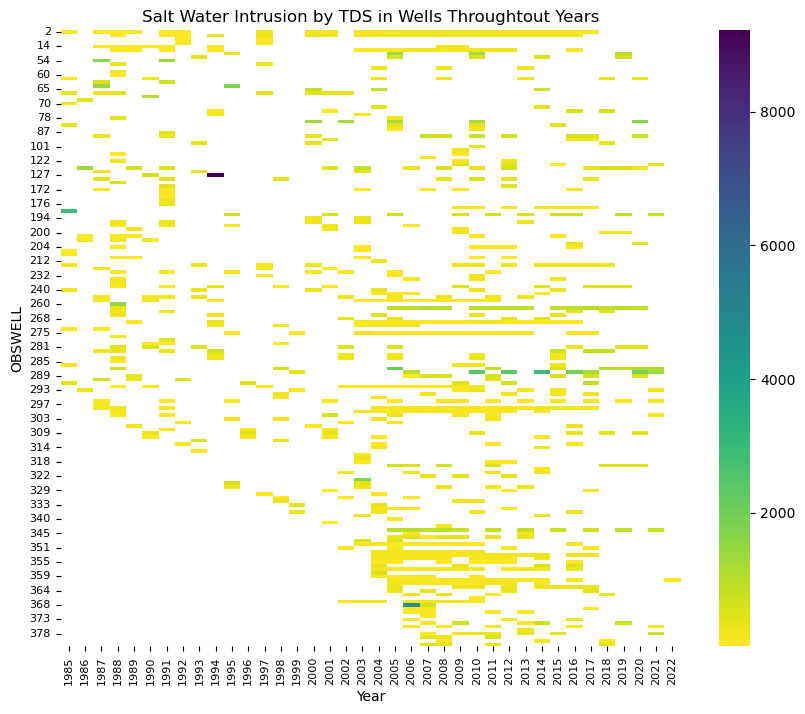

<Figure size 1000x800 with 0 Axes>

In [39]:
SWItds = df_SWICLorSCorSCtime.pivot_table(index="OBSWELL", columns="Year", values="Residue Filterable 1.0u")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(SWItds, annot=False, cmap='viridis_r')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Salt Water Intrusion by TDS in Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/SWIheatmapTDSSWICLorSC.png')